In [1]:
import glob
import os
import subprocess
import pandas as pd
from pathlib import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import json
import re

In [2]:
##### Functions
def extract_id(model_name):
    parts = model_name.split("_")
    seed = None
    model_num = None
    for i, part in enumerate(parts):
        if part == "seed":
            seed = parts[i + 1]
        elif part == "model":
            model_num = parts[i + 1]
    return seed, model_num

def extract_confidences(summary_json_file):
    # Parse the summary confidence JSON files and extrct the relevant information to append to the model_info_df DataFrame
    with open(summary_json_file, "r") as f:
        summary_data = json.load(f)

    chain_iptm = summary_data.get("chain_iptm", [None] * 5)
    chain_iptm = list(chain_iptm) + [None] * (5 - len(chain_iptm))
    chain_ptm = summary_data.get("chain_ptm", [None] * 5)
    chain_ptm = list(chain_ptm) + [None] * (5 - len(chain_ptm))
    # chain pair iptm is an squared matrix of 5x5, where each pair of chains (i,j)
    # have their own iptm value
    chain_pair_iptm = summary_data.get("chain_pair_iptm", [[None] * 5] * 5)

    confidences = {
        "iptm": summary_data.get("iptm"),
        "ptm": summary_data.get("ptm"),
        "ranking_score": summary_data.get("ranking_score"),
        "chainA_iptm": chain_iptm[0],
        "chainB_iptm": chain_iptm[1],
        "chainC_iptm": chain_iptm[2],
        "chainD_iptm": chain_iptm[3],
        "chainE_iptm": chain_iptm[4],
        "chainA_ptm": chain_ptm[0],
        "chainB_ptm": chain_ptm[1],
        "chainC_ptm": chain_ptm[2],
        "chainD_ptm": chain_ptm[3],
        "chainE_ptm": chain_ptm[4],
        "fraction_disordered": summary_data.get("fraction_disordered"),
        "has_clash": summary_data.get("has_clash"),
        "chain_AB_iptm": chain_pair_iptm[0][1],
        "chain_AC_iptm": chain_pair_iptm[0][2],
        "chain_BC_iptm": chain_pair_iptm[1][2],
    }

    return confidences

def extract_full_confidences(confidences_json_file):
    # Parse the full data JSON files and extract the relevant information to append to the model_info_df DataFrame
    with open(confidences_json_file, "r") as f:
        confidences_data = json.load(f)

    atom_plddts = confidences_data.get("atom_plddts", [])
    confidences = {
        "mean_atom_plddts": float(np.mean(atom_plddts)) if atom_plddts else None,
    }

    return confidences

def run_af3_ipsae(model_df, pae_cutoff=10, dist_cutoff=10, limit=1):
    """Run ipSAE for the first `limit` rows that have valid input paths."""
    pae_tag = f"{int(pae_cutoff):02d}"
    dist_tag = f"{int(dist_cutoff):02d}"

    for idx, row in model_df.head(limit).iterrows():
        json_file = row["full_data_json_path"]
        cif_file = row["cif_path"]
        seed = row["seed"]
        model_num = row["model_num"]
        model_name = row["model_name"]

        if any(pd.isna(value) for value in (json_file, cif_file)):
            print(f"Skipping row {idx}: missing input paths")
            continue

        cif_path = Path(cif_file)
        output_base = cif_path.with_suffix("")
        output_base = output_base.parent / f"{output_base.name}_{pae_tag}_{dist_tag}"

        expected_outputs = [
            output_base.with_suffix(".txt"),
            output_base.with_suffix(".pml"),
            output_base.with_name(f"{output_base.name}_byres.txt"),
        ]

        if all(path.exists() for path in expected_outputs):
            print(f"ipSAE outputs already exist for {model_name}, skipping execution")
            continue

        try:
            subprocess.run(
                [
                    "python3",
                    IPSAE_PY,
                    str(json_file),
                    str(cif_path),
                    str(pae_cutoff),
                    str(dist_cutoff),
                ],
                check=True,
            )
        except subprocess.CalledProcessError as exc:
            print(f"af3 ipSAE failed for {model_name}: {exc}")

def summarize_ipsae_output(txt_path):
    df = pd.read_csv(txt_path, sep=r"\s+", comment="#")
    df = df.rename(columns={"Chn1": "chain_1", "Chn2": "chain_2"})

    df["pair"] = df.apply(
        lambda row: "-".join(sorted([str(row["chain_1"]), str(row["chain_2"])])),
        axis=1,
    )

    summary = (
        df.groupby("pair")
        .agg(
            ipSAE_mean=("ipSAE", "mean"),
            ipSAE_min=("ipSAE", "min"),
            ipSAE_max=("ipSAE", "max"),
            pDockQ2_mean=("pDockQ2", "mean"),
            pDockQ2_min=("pDockQ2", "min"),
            pDockQ2_max=("pDockQ2", "max"),
            LIS_mean=("LIS", "mean"),
            LIS_min=("LIS", "min"),
            LIS_max=("LIS", "max"),
            ipTM_af=("ipTM_af", "first"),
        )
        .reset_index()
    )

    return summary

def append_ipsae_output(
    model_df,
    pae_cutoff=10,
    dist_cutoff=10,
    pair="A-B"
):
    """
    pair puede ser:
        "A-B"
    o
        ["A-B", "A-C", "B-C"]
    """

    if isinstance(pair, str):
        pairs = [pair]
    else:
        pairs = pair

    pae_tag = f"{int(pae_cutoff):02d}"
    dist_tag = f"{int(dist_cutoff):02d}"

    for idx, row in model_df.iterrows():
        model_name = row["model_name"]
        folder_path = row["folder_path"]

        if pd.isna(folder_path):
            print(f"Skipping row {idx} ({model_name}): missing folder path")
            continue

        expected_txt = Path(folder_path) / f"{model_name}_{pae_tag}_{dist_tag}.txt"

        if not expected_txt.exists():
            print(f"Skipping row {idx} ({model_name}): ipSAE output not found at {expected_txt}")
            continue

        if expected_txt.stat().st_size == 0:
            print(f"Skipping row {idx} ({model_name}): ipSAE output file is empty")
            continue

        try:
            summary_df = summarize_ipsae_output(expected_txt)
        except pd.errors.EmptyDataError:
            print(f"Skipping row {idx} ({model_name}): no columns to parse in {expected_txt}")
            continue
        except Exception as exc:
            print(f"Skipping row {idx} ({model_name}): failed to parse {expected_txt} ({exc})")
            continue

        if summary_df.empty or "pair" not in summary_df.columns:
            print(f"Skipping row {idx} ({model_name}): empty/invalid ipSAE summary")
            continue

        for current_pair in pairs:

            pair_df = summary_df[summary_df["pair"] == current_pair]

            if pair_df.empty:
                print(
                    f"Skipping row {idx} ({model_name}): "
                    f"no {current_pair} pair found in ipSAE summary"
                )
                continue

            for metric in ["ipSAE", "pDockQ2", "LIS"]:
                for stat in ["mean", "min", "max"]:

                    source_col = f"{metric}_{stat}"
                    target_col = f"{metric}_{stat}_{current_pair}"

                    if source_col in pair_df.columns:
                        model_df.loc[idx, target_col] = pair_df.iloc[0][source_col]
            if "ipTM_af" in pair_df.columns:
                model_df.loc[idx, f"ipTM_af_{current_pair}"] = pair_df.iloc[0]["ipTM_af"]

def merge_cluster_info(model_df, cluster_df):
    """Merge the cluster assignments from cluster_df into model_df based on model_name."""
    merged_df = pd.merge(model_df, cluster_df[["model", "cluster"]], left_on="model_name", right_on="model", how="left")
    merged_df = merged_df.drop(columns=["model"])
    return merged_df

def plot_clusters_scores(
    model_df, metrics,
    pair="A-B", clusters=[14, 15],
    file_title="/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/analysis/AF3S_cluster_score_distributions.png",
    fig_w =2.5, fig_h=5.5
):
    """
    Plot score distributions for selected metrics using a Yes/No cluster grouping.
    Yes: models whose cluster is in `clusters`; No: all other models.
    """
    from matplotlib.font_manager import fontManager, FontProperties
    from matplotlib.patches import Patch
    import warnings
    warnings.filterwarnings('ignore')  # Suppress all warnings

    font_path = '/home/gaecri/Documents/Projects/Utils/Fonts/DIN_Condensed_Bold.ttf'
    fontManager.addfont(font_path)
    prop = FontProperties(fname=font_path)
    sns.set_theme(style="ticks", font=prop.get_name())

    df_plot = model_df.copy()
    df_plot["cluster_group"] = df_plot["cluster"].apply(lambda x: "Yes" if x in clusters else "No")

    palette = {"Yes": "#4C9BE8", "No": "#9A9A9A"}
    group_order = ["Yes", "No"]
    num_metrics = len(metrics)
    fig, axes = plt.subplots(1, num_metrics, figsize=(fig_w * num_metrics, fig_h), sharey=True)

    if num_metrics == 1:
        axes = [axes]

    for ax, metric in zip(axes, metrics):
        if metric not in df_plot.columns:
            ax.set_title(f"{metric} (not found)")
            ax.set_ylim(0, 1)
            # ax.set_xticks([])
            ax.set_xlabel("")
            continue

        metric_df = df_plot[["cluster_group", metric]].dropna()

        sns.violinplot(
            data=metric_df, x="cluster_group", y=metric,
            order=group_order, palette=palette,
            inner="quart", cut=0, bw_adjust=0.5,
            linewidth=0.1, scale="width", ax=ax,)

        sns.stripplot(
            data=metric_df, x="cluster_group", y=metric,
            order=group_order, color="black", alpha=0.30,
            size=2.5, jitter=0.15, ax=ax,)

        ax.set_title(metric)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_ylim(0, 1)
        ax.set_xticks([])
        ax.yaxis.grid(True, linestyle="-", alpha=0.7)

        # hide y-axis ticks/labels for all axes except the first
        if ax is not axes[0]:
            ax.tick_params(axis="y", left=False, labelleft=False)
            ax.set_ylabel("")

    legend_handles = [
        Patch(facecolor=palette["Yes"], edgecolor="black", label=f"Protease driven recognition (n = {len(df_plot[df_plot['cluster_group'] == 'Yes'])})"),
        Patch(facecolor=palette["No"], edgecolor="black", label=f"Fab' driven recognition (n = {len(df_plot[df_plot['cluster_group'] == 'No'])})"),
    ]
    # fig.legend(
    #     handles=legend_handles,
    #     # title="Binding mode",
    #     loc="lower center",
    #     ncols=2,
    #     bbox_to_anchor=(0.5, 0.01),
    #     # change color of the legend box
    #     frameon=True, framealpha=0.9, edgecolor="white",
    #     # text size
    #     fontsize=14
    #     )

    # fig.supxlabel("Binding mode")
    # fig.suptitle(f"Distribution of scores for {pair} pair", fontsize=18)
    # plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.tight_layout()
    plt.savefig(f"{file_title}.png", dpi=350)
    plt.savefig(f"{file_title}.pdf", dpi=350)
    plt.show()
    
    print("Mean scores for Fab' driven recognition (No):")
    print(df_plot[df_plot["cluster_group"] == "No"][metrics].mean())
    print("Max scores for Fab' driven recognition (No):")
    print(df_plot[df_plot["cluster_group"] == "No"][metrics].max())
    print("Min scores for Fab' driven recognition (No):")
    print(df_plot[df_plot["cluster_group"] == "No"][metrics].min())

    print("Mean scores for Protease driven recognition (Yes):")
    print(df_plot[df_plot["cluster_group"] == "Yes"][metrics].mean())
    print("Max scores for Protease driven recognition (Yes):")
    print(df_plot[df_plot["cluster_group"] == "Yes"][metrics].max())
    print("Min scores for Protease driven recognition (Yes):")
    print(df_plot[df_plot["cluster_group"] == "Yes"][metrics].min())

In [3]:
######## New functions
def plot_clusters_energies(
    model_df, metrics,
    clusters=[14, 15],
    file_title="AF3S_cluster_energies_distributions",
    fig_w =2.5, fig_h=5.5,
    ylims=None, set_font=False,
    ):
    """
    Plot score distributions for selected metrics using a Yes/No cluster grouping.
    Yes: models whose cluster is in `clusters`; No: all other models.
    """
    from matplotlib.font_manager import fontManager, FontProperties
    from matplotlib.patches import Patch
    import warnings
    warnings.filterwarnings('ignore')  # Suppress all warnings

    if set_font:
        font_path = '/home/gaecri/Documents/Projects/Utils/Fonts/DIN_Condensed_Bold.ttf'
        fontManager.addfont(font_path)
        prop = FontProperties(fname=font_path)
        sns.set_theme(style="ticks", font=prop.get_name())
    else:
        sns.set_theme(style="ticks")

    df_plot = model_df.copy()
    df_plot["cluster_group"] = df_plot["cluster"].apply(lambda x: "Yes" if x in clusters else "No")

    palette = {"Yes": "#4C9BE8", "No": "#9A9A9A"}
    group_order = ["Yes", "No"]
    num_metrics = len(metrics)
    fig, axes = plt.subplots(1, num_metrics, figsize=(fig_w * num_metrics, fig_h), sharey=True)

    if num_metrics == 1:
        axes = [axes]

    for ax, metric in zip(axes, metrics):
        if metric not in df_plot.columns:
            ax.set_title(f"{metric} (not found)")
            if ylims:
                ax.set_ylim(ylims)
            # ax.set_xticks([])
            ax.set_xlabel("")
            continue

        metric_df = df_plot[["cluster_group", metric]].dropna()

        sns.violinplot(
            data=metric_df, x="cluster_group", y=metric,
            order=group_order, palette=palette,
            inner="quart", cut=0, bw_adjust=0.5,
            linewidth=0.1, scale="width", ax=ax,)

        sns.stripplot(
            data=metric_df, x="cluster_group", y=metric,
            order=group_order, color="black", alpha=0.30,
            size=2.5, jitter=0.15, ax=ax,)

        ax.set_title(metric)
        ax.set_xlabel("")
        ax.set_ylabel("")
        if ylims:
            ax.set_ylim(ylims)
        
        ax.set_xticks([])
        ax.yaxis.grid(True, linestyle="-", alpha=0.7)

        # hide y-axis ticks/labels for all axes except the first
        if ax is not axes[0]:
            ax.tick_params(axis="y", left=False, labelleft=False)
            ax.set_ylabel("")

    legend_handles = [
        Patch(facecolor=palette["Yes"], edgecolor="black", label=f"Protease driven recognition (n = {len(df_plot[df_plot['cluster_group'] == 'Yes'])})"),
        Patch(facecolor=palette["No"], edgecolor="black", label=f"Fab' driven recognition (n = {len(df_plot[df_plot['cluster_group'] == 'No'])})"),
    ]
    # fig.legend(
    #     handles=legend_handles,
    #     # title="Binding mode",
    #     loc="lower center",
    #     ncols=2,
    #     bbox_to_anchor=(0.5, 0.01),
    #     # change color of the legend box
    #     frameon=True, framealpha=0.9, edgecolor="white",
    #     # text size
    #     fontsize=14
    #     )

    # fig.supxlabel("Binding mode")
    # fig.suptitle(f"Distribution of scores for {pair} pair", fontsize=18)
    # plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.tight_layout()
    plt.savefig(f"{file_title}.png", dpi=350)
    plt.savefig(f"{file_title}.pdf", dpi=350)
    plt.show()
    
    print("Mean scores for Fab' driven recognition (No):")
    print(df_plot[df_plot["cluster_group"] == "No"][metrics].mean())
    print("Max scores for Fab' driven recognition (No):")
    print(df_plot[df_plot["cluster_group"] == "No"][metrics].max())
    print("Min scores for Fab' driven recognition (No):")
    print(df_plot[df_plot["cluster_group"] == "No"][metrics].min())

    print("Mean scores for Protease driven recognition (Yes):")
    print(df_plot[df_plot["cluster_group"] == "Yes"][metrics].mean())
    print("Max scores for Protease driven recognition (Yes):")
    print(df_plot[df_plot["cluster_group"] == "Yes"][metrics].max())
    print("Min scores for Protease driven recognition (Yes):")
    print(df_plot[df_plot["cluster_group"] == "Yes"][metrics].min())

def plot_correlations_metrics(
    df, metrics,
    clusters=[14, 15],
    set_font=False,
    fig_name="correlation_metrics",
):
    """
    Plot the correlation between selected metrics using a scatter plot matrix.
    If clusters are provided, color the points based on whether they belong to the specified clusters or not.
    """
    from matplotlib.font_manager import fontManager, FontProperties
    import warnings
    warnings.filterwarnings('ignore')  # Suppress all warnings

    if set_font:
        font_path = '/home/gaecri/Documents/Projects/Utils/Fonts/DIN_Condensed_Bold.ttf'
        fontManager.addfont(font_path)
        prop = FontProperties(fname=font_path)
        sns.set_theme(style="ticks", font=prop.get_name())
    else:
        sns.set_theme(style="ticks")

    df_plot = df.copy()
    df_plot["cluster_group"] = df_plot["cluster"].apply(
        lambda x: "Yes" if x in clusters else "No"
    )

    palette = {"Yes": "#4C9BE8", "No": "#9A9A9A"}
    group_order = ["Yes", "No"]

    g = sns.pairplot(
            data=df_plot,
            vars=metrics,
            hue="cluster_group",
            palette=palette,
            hue_order=group_order,
            plot_kws={"alpha": 0.5, "s": 20},
            diag_kind="kde",
            diag_kws={"fill": True},
        )
    if g._legend is not None:
        g._legend.remove()

    plt.savefig(
        f"{fig_name}.png", dpi=300, bbox_inches="tight")
    plt.savefig(
        f"{fig_name}.pdf", dpi=300, bbox_inches="tight")
    plt.show()

def calc_Z_scores_for_models(
    model_df, metrics_list
):
    """
    Calculate the Z-scores for each model in the DataFrame based on the provided metrics list.
    Z represents the z-score value for a given data point X, μ is the mean, and σ the standard 
    deviation of the studied dataset or that of a reference one. By applying the z-score to 
    scoring functions like AlphaFold confidences and pyDock-1VDW energies, 
    we can derive ZAF-MC (z-score of model confidence) and ZpyDock-1VDW (z-score of pyDock total
    energy). After this standardization, the z-scores retain the same sign 
    interpretation as their raw counterparts: High (positive) ZAF-MC values indicate reliable models, 
    and low (negative) ZpyDock-1VDW values suggest better models in terms of energy.
    """
    mean_values = model_df[metrics_list].mean()
    std_devs = model_df[metrics_list].std()

    z_scores_df = pd.DataFrame(index=model_df.index)

    for metric in metrics_list:
        if metric in mean_values and metric in std_devs:
            z_scores_df[f"Z_{metric}"] = (model_df[metric] - mean_values[metric]) / std_devs[metric]
        else:
            z_scores_df[f"Z_{metric}"] = None

    return z_scores_df

def plot_rank_vs_rank(
    model_df, metric_x, metric_y,
    clusters=(14, 15),
    limit_xrank=None, limit_yrank=None,
    file_path="./"
):
    from scipy.stats import spearmanr, kendalltau
    import seaborn as sns
    import matplotlib.pyplot as plt

    df = model_df.copy()

    # Keep only rows usable for both metrics and cluster labeling
    df = df.dropna(subset=[metric_x, metric_y, "cluster"])

    df["rank_x"] = df[metric_x].rank(ascending=False, method="average")
    df["rank_y"] = df[metric_y].rank(ascending=False, method="average")

    rho, rho_pval = spearmanr(df["rank_x"], df["rank_y"])
    tau, tau_pval = kendalltau(df["rank_x"], df["rank_y"])

    df["cluster_group"] = df["cluster"].apply(
        lambda x: "Yes" if x in clusters else "No"
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    sns.scatterplot(
        data=df,
        x="rank_x",
        y="rank_y",
        hue="cluster_group",
        palette={"Yes": "#4C9BE8", "No": "#9A9A9A"},
        alpha=0.5,
        s=20,
        ax=ax,
    )

    # Fitted linear trend line, with 95% confidence interval
    sns.regplot(
        data=df,
        x="rank_x",
        y="rank_y",
        scatter=False,
        color="black",
        line_kws={"linewidth": 2, "label": "Linear fit"},
        ax=ax,
    )

    # Perfect rank agreement: rank_y == rank_x
    limits = [
        min(df["rank_x"].min(), df["rank_y"].min()),
        max(df["rank_x"].max(), df["rank_y"].max()),
    ]

    ax.plot(
        limits,
        limits,
        linestyle="--",
        color="black",
        alpha=0.7,
        # label="Perfect agreement (y = x)",
    )

    ax.set_xlabel(f"Rank based on {metric_x}")
    ax.set_ylabel(f"Rank based on {metric_y}")
    ax.set_title(
        f"Rank correlation\n"
        f"Spearman ρ = {rho:.3f} (p={rho_pval:.3e}), "
        f"Kendall τ = {tau:.3f} (p={tau_pval:.3e})"
    )

    if limit_xrank is not None and limit_yrank is not None:
        ax.set_xlim(limit_xrank[0], limit_xrank[1])
        ax.set_ylim(limit_yrank[0], limit_yrank[1])

    ax.invert_xaxis()
    ax.invert_yaxis()
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"{file_path}rank_vs_rank_{metric_x}_vs_{metric_y}.png", dpi=350, bbox_inches="tight")
    plt.show()

In [4]:
af_models = [
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1",
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_2",
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_3",
    "/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_4"
    ]

cif_files = [cif for i in af_models for cif in glob.glob(os.path.join(i, "**/*.cif"), recursive=False)]
confidences_jsons = [json_file for i in af_models for json_file in glob.glob(os.path.join(i, "**/*_full_data_*.json"), recursive=False)]
summary_jsons = [json_file for i in af_models for json_file in glob.glob(os.path.join(i, "**/*_summary_confidences_*.json"), recursive=False)]

print(f"Found {len(cif_files)} mmCIF files for analysis.")
print(f"Found {len(confidences_jsons)} confidence JSON files for analysis.")
print(f"Found {len(summary_jsons)} summary JSON files for analysis.")

Found 500 mmCIF files for analysis.
Found 500 confidence JSON files for analysis.
Found 500 summary JSON files for analysis.


In [ ]:
# Matrix with 500x500 RMSD values for all pairwise comparisons of the 500 models
rmsd_df = pd.read_csv(("500x500_rmsd_matrix.csv"), index_col=0)
rmsd_results = rmsd_df.values
labels = rmsd_df.index.tolist()

In [5]:
# Create a DataFrame to hold the extracted information
data = []
for label in labels:
    seed, model_num = extract_id(label)
    data.append({"model_name": label, "seed": seed, "model_num": model_num})
model_info_df = pd.DataFrame(data)

In [7]:
# Loop through summary JSON files, extract confidences, and map to model_info_df
for summary_json in summary_jsons:
    stem = Path(summary_json).stem

    if "_summary_confidences_" in stem:
        prefix, model_num = stem.rsplit("_summary_confidences_", 1)

    model_name = f"{prefix}_model_{model_num}"  # matches model_info_df["model_name"]
    confidences = extract_confidences(summary_json)
    mask = model_info_df["model_name"] == model_name
    if mask.any():
        model_info_df.loc[mask, list(confidences.keys())] = list(confidences.values())

In [9]:
# Loop through full data JSON files, extract confidences, and map to model_info_df
for confidences_json in confidences_jsons:
    stem = Path(confidences_json).stem  # filename without .json

    if "_full_data_" in stem:
        prefix, model_num = stem.rsplit("_full_data_", 1)

    model_name = f"{prefix}_model_{model_num}"  # matches model_info_df["model_name"]
    confidences = extract_full_confidences(confidences_json)
    mask = model_info_df["model_name"] == model_name
    if mask.any():
        model_info_df.loc[mask, list(confidences.keys())] = list(confidences.values())

In [10]:
# Append the paths of the folder, .cif, summary JSON, and full data JSON files to the model_info_df DataFrame
model_info_df["folder_path"] = None
model_info_df["cif_path"] = None
model_info_df["summary_json_path"] = None
model_info_df["full_data_json_path"] = None

for cif in cif_files:
    stem = Path(cif).stem  # filename without .cif
    if "_model_" in stem:
        prefix, model_num = stem.rsplit("_model_", 1)
        model_name = f"{prefix}_model_{model_num}"
        mask = model_info_df["model_name"] == model_name
        if mask.any():
            model_info_df.loc[mask, "folder_path"] = str(Path(cif).parent)
            model_info_df.loc[mask, "cif_path"] = cif

for summary_json in summary_jsons:
    stem = Path(summary_json).stem  # filename without .json
    if "_summary_confidences_" in stem:
        prefix, model_num = stem.rsplit("_summary_confidences_", 1)
        model_name = f"{prefix}_model_{model_num}"
        mask = model_info_df["model_name"] == model_name
        if mask.any():
            model_info_df.loc[mask, "summary_json_path"] = summary_json

for confidences_json in confidences_jsons:
    stem = Path(confidences_json).stem  # filename without .json
    if "_full_data_" in stem:
        prefix, model_num = stem.rsplit("_full_data_", 1)
        model_name = f"{prefix}_model_{model_num}"
        mask = model_info_df["model_name"] == model_name
        if mask.any():
            model_info_df.loc[mask, "full_data_json_path"] = confidences_json


In [ ]:
# model_info_df.to_csv("AF3S_scores.csv", index=False)

In [ ]:
model_info_df = pd.read_csv("AF3S_scores.csv")

In [6]:
model_info_df.head()

,model_name,seed,model_num,iptm,ptm,ranking_score,chainA_iptm,chainB_iptm,chainC_iptm,chainD_iptm,...,chainC_ptm,chainD_ptm,chainE_ptm,fraction_disordered,has_clash,mean_atom_plddts,folder_path,cif_path,summary_json_path,full_data_json_path
0,fold_igase_iga2_wt_seed_204865_model_2,204865,2,0.64,0.73,0.65,0.77,0.57,0.53,0.63,...,0.63,NaN,NaN,0.0,0.0,87.034660,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...
1,fold_igase_iga2_wt_seed_204865_model_0,204865,0,0.64,0.73,0.66,0.77,0.58,0.53,0.63,...,0.62,NaN,NaN,0.0,0.0,87.085167,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...
2,fold_igase_iga2_wt_seed_204865_model_3,204865,3,0.63,0.73,0.65,0.77,0.57,0.53,0.63,...,0.62,NaN,NaN,0.0,0.0,86.999987,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...
3,fold_igase_iga2_wt_seed_204865_model_1,204865,1,0.64,0.73,0.66,0.77,0.58,0.53,0.63,...,0.63,NaN,NaN,0.0,0.0,87.213312,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...
4,fold_igase_iga2_wt_seed_204865_model_4,204865,4,0.63,0.72,0.65,0.76,0.56,0.52,0.62,...,0.63,NaN,NaN,0.0,0.0,87.132426,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...,/home/gaecri/Documents/Projects/IgAses/IgAse_I...


In [120]:
IPSAE_PY = '/home/gaecri/Documents/Projects/Softwares/utils/ipsae.py'

In [25]:
# run_af3_ipsae(
#     model_info_df, limit=500,
#     pae_cutoff=10, dist_cutoff=10
#     )

In [ ]:
# Example of ipSAE output summary
summarize_ipsae_output("/home/gaecri/Documents/Projects/IgAses/IgAse_IgA2_modelling/AF3_server/outs/IgAse_IgA2_wt_multiple_seeds_1/igase_iga2_wt_seed_20193/fold_igase_iga2_wt_seed_20193_model_0_10_10.txt")

,pair,ipSAE_mean,ipSAE_min,ipSAE_max,pDockQ2_mean,pDockQ2_min,pDockQ2_max,LIS_mean,LIS_min,LIS_max
0,A-B,0.013450,0.013045,0.013652,0.028200,0.0274,0.0286,0.057067,0.0500,0.0641
1,A-C,0.011439,0.011194,0.011561,0.034100,0.0339,0.0342,0.055433,0.0548,0.0561
2,B-C,0.671980,0.641213,0.687363,0.610467,0.5770,0.6272,0.495700,0.4916,0.4998


In [176]:
append_ipsae_output(
    model_info_df,
    pae_cutoff=10,
    dist_cutoff=10,
    pair=["A-B", "A-C", "B-C"]
)

In [ ]:
# model_info_df.to_csv("AF3S_ipSAE_full_scores.csv", index=False)

In [7]:
model_info_df = pd.read_csv("AF3S_ipSAE_full_scores.csv")

In [ ]:
clusters_scores = pd.read_csv(
    "clusters_scores.csv"
    )

model_info_with_clusters = merge_cluster_info(model_info_df, clusters_scores)
model_info_with_clusters.to_csv(
    "AF3S_full_scores_clusters.csv", 
    index=False)

In [8]:
model_info_with_clusters = pd.read_csv(
    "AF3S_full_scores_clusters.csv"
    )

In [9]:
model_info_with_clusters.head()

,model_name,seed,model_num,iptm,ptm,ranking_score,chainA_iptm,chainB_iptm,chainC_iptm,chainD_iptm,...,pDockQ2_mean_B-C,pDockQ2_min_B-C,pDockQ2_max_B-C,LIS_mean_B-C,LIS_min_B-C,LIS_max_B-C,ipTM_af_A-B,ipTM_af_A-C,ipTM_af_B-C,cluster
0,fold_igase_iga2_wt_seed_204865_model_2,204865,2,0.64,0.73,0.65,0.77,0.57,0.53,0.63,...,0.586167,0.5375,0.6105,0.528900,0.5223,0.5355,0.60,0.55,0.68,14
1,fold_igase_iga2_wt_seed_204865_model_0,204865,0,0.64,0.73,0.66,0.77,0.58,0.53,0.63,...,0.581667,0.5320,0.6065,0.524700,0.5171,0.5323,0.61,0.56,0.68,14
2,fold_igase_iga2_wt_seed_204865_model_3,204865,3,0.63,0.73,0.65,0.77,0.57,0.53,0.63,...,0.600633,0.5617,0.6201,0.529800,0.5242,0.5354,0.60,0.55,0.68,14
3,fold_igase_iga2_wt_seed_204865_model_1,204865,1,0.64,0.73,0.66,0.77,0.58,0.53,0.63,...,0.585500,0.5349,0.6108,0.530667,0.5252,0.5361,0.61,0.56,0.68,14
4,fold_igase_iga2_wt_seed_204865_model_4,204865,4,0.63,0.72,0.65,0.76,0.56,0.52,0.62,...,0.568600,0.5236,0.5911,0.534500,0.5257,0.5433,0.59,0.54,0.68,14


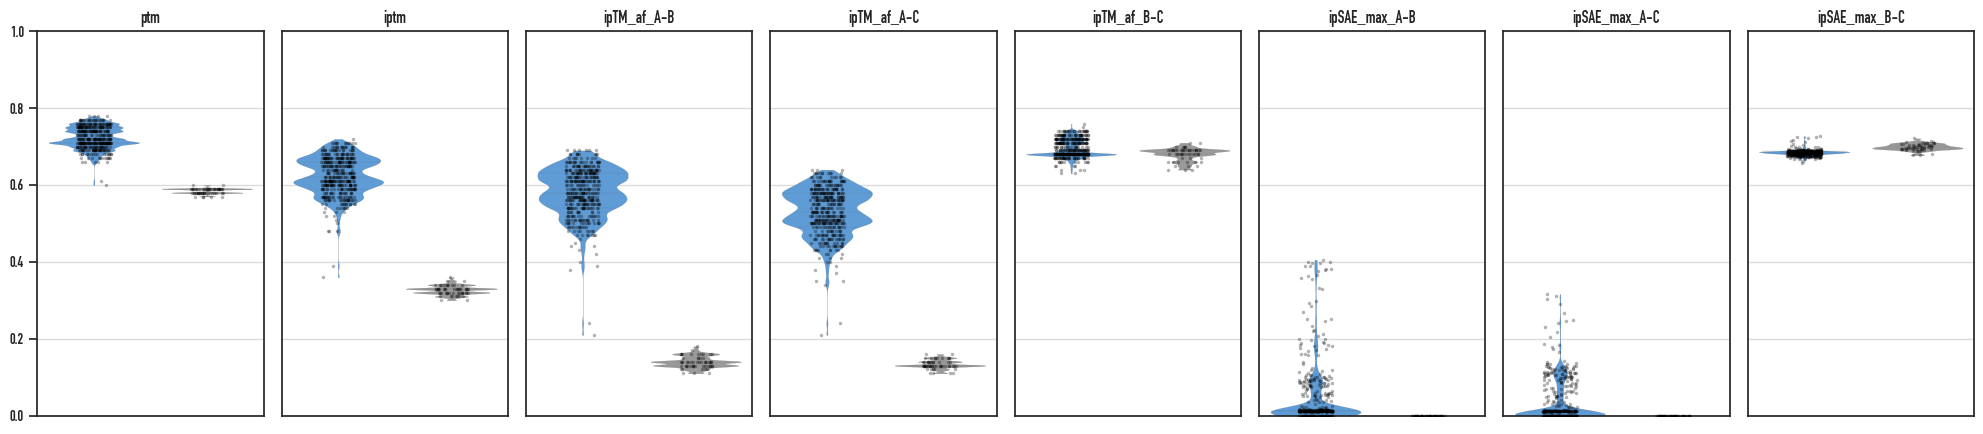

Mean scores for Fab' driven recognition (No):
ptm              0.584737
iptm             0.326667
ipTM_af_A-B      0.139123
ipTM_af_A-C      0.134035
ipTM_af_B-C      0.680175
ipSAE_max_A-B    0.000000
ipSAE_max_A-C    0.000000
ipSAE_max_B-C    0.699273
dtype: float64
Max scores for Fab' driven recognition (No):
ptm              0.600000
iptm             0.360000
ipTM_af_A-B      0.180000
ipTM_af_A-C      0.160000
ipTM_af_B-C      0.710000
ipSAE_max_A-B    0.000000
ipSAE_max_A-C    0.000000
ipSAE_max_B-C    0.721458
dtype: float64
Min scores for Fab' driven recognition (No):
ptm              0.570000
iptm             0.300000
ipTM_af_A-B      0.110000
ipTM_af_A-C      0.110000
ipTM_af_B-C      0.640000
ipSAE_max_A-B    0.000000
ipSAE_max_A-C    0.000000
ipSAE_max_B-C    0.677623
dtype: float64
Mean scores for Protease driven recognition (Yes):
ptm              0.723318
iptm             0.624041
ipTM_af_A-B      0.580181
ipTM_af_A-C      0.530023
ipTM_af_B-C      0.696072
ipSAE_max_A-B 

In [10]:
metrics_plot = [
    "ptm", "iptm",
    # "chainA_iptm", "chainB_iptm", "chainC_iptm",
    "ipTM_af_A-B", "ipTM_af_A-C", "ipTM_af_B-C",
    # "ipSAE_min", "ipSAE_max",
    # "pDockQ2_mean_A-B", "pDockQ2_mean_A-C", "pDockQ2_mean_B-C", 
    # "LIS_mean_A-B", "LIS_mean_A-C", "LIS_mean_B-C",
    # "ipSAE_min_A-B", "ipSAE_min_A-C", "ipSAE_min_B-C", 
    "ipSAE_max_A-B", "ipSAE_max_A-C", "ipSAE_max_B-C",
    ]

plot_clusters_scores(
    model_info_with_clusters, metrics_plot,
    clusters=[14, 15],
    file_title="plots/AF3S_cluster_score_distributions",
    fig_w=2.5, fig_h=4.5,
    )

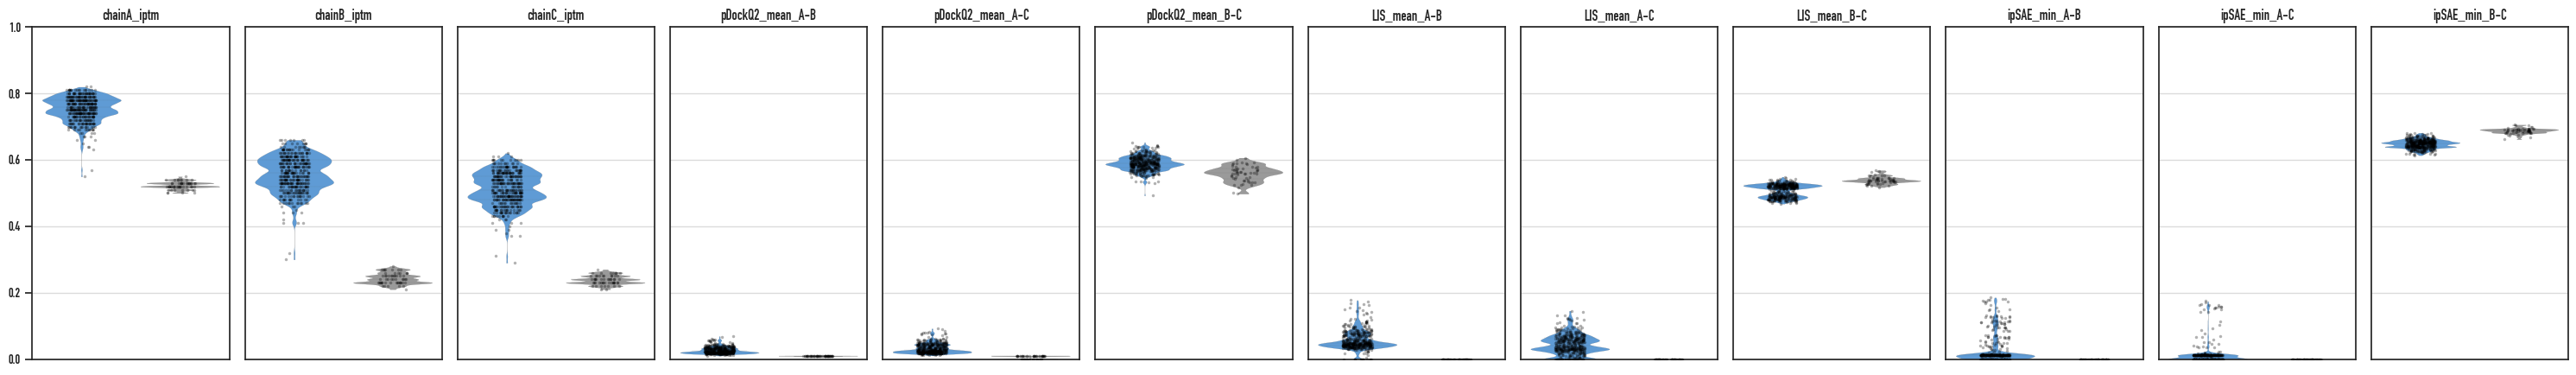

Mean scores for Fab' driven recognition (No):
chainA_iptm         0.523684
chainB_iptm         0.243333
chainC_iptm         0.238421
pDockQ2_mean_A-B    0.009411
pDockQ2_mean_A-C    0.005553
pDockQ2_mean_B-C    0.558713
LIS_mean_A-B        0.000000
LIS_mean_A-C        0.000000
LIS_mean_B-C        0.539097
ipSAE_min_A-B       0.000000
ipSAE_min_A-C       0.000000
ipSAE_min_B-C       0.687678
dtype: float64
Max scores for Fab' driven recognition (No):
chainA_iptm         0.550000
chainB_iptm         0.280000
chainC_iptm         0.270000
pDockQ2_mean_A-B    0.009900
pDockQ2_mean_A-C    0.009733
pDockQ2_mean_B-C    0.606400
LIS_mean_A-B        0.000000
LIS_mean_A-C        0.000000
LIS_mean_B-C        0.568667
ipSAE_min_A-B       0.000000
ipSAE_min_A-C       0.000000
ipSAE_min_B-C       0.705959
dtype: float64
Min scores for Fab' driven recognition (No):
chainA_iptm         0.500000
chainB_iptm         0.210000
chainC_iptm         0.210000
pDockQ2_mean_A-B    0.009000
pDockQ2_mean_A-C    0.

In [12]:
metrics_plot = [
    # "ptm", "iptm",
    "chainA_iptm", "chainB_iptm", "chainC_iptm",
    # "ipTM_af_A-B", "ipTM_af_A-C", "ipTM_af_B-C",
    # "ipSAE_min", "ipSAE_max",
    "pDockQ2_mean_A-B", "pDockQ2_mean_A-C", "pDockQ2_mean_B-C", 
    "LIS_mean_A-B", "LIS_mean_A-C", "LIS_mean_B-C",
    "ipSAE_min_A-B", "ipSAE_min_A-C", "ipSAE_min_B-C", 
    # "ipSAE_max_A-B", "ipSAE_max_A-C", "ipSAE_max_B-C",
    ]

plot_clusters_scores(
    model_info_with_clusters, metrics_plot,
    clusters=[14, 15],
    file_title="plots/AF3S_cluster_score_distributions_2",
    fig_w=2.5, fig_h=4.5,
    )

In [ ]:
# Calculate TM scores for all models against the recognition structure and precatalytic structure and append to model_info_df
# using the same approach as for ipSAE, by running an external script that calculates TMscores and outputs a .txt file for each model, then parsing those .txt files to extract the
USALIGN = "/home/gaecri/Software/USalign/USalign"
PRECAT = "IgAse23-Fabpr_precat_last.pdb"
RECOG = "IgAse23-Fabpr_recog_last.pdb"

# create columms TMscore_precat and TMscore_recog in model_info_with_clusters
model_info_with_clusters["TMscore_precat_0"] = None
model_info_with_clusters["TMscore_precat_1"] = None
model_info_with_clusters["TMscore_recog_0"] = None
model_info_with_clusters["TMscore_recog_1"] = None

txt_path = "tmscores.txt"

for idx, row in model_info_with_clusters.iterrows():
    cif_path = row["cif_path"]
    model_name = row["model_name"]

    if pd.isna(cif_path):
        print(f"Skipping row {idx} ({model_name}): missing CIF path")
        continue

    try:
        result_precat = subprocess.run(
            [USALIGN, cif_path, PRECAT, "-mm", "1", "-ter", "1", "-outfmt", "1"],
            capture_output=True,
            text=True,
            check=True)
        with open(txt_path, "a") as f:
            f.write(f"- Model: {model_name}\n")
            f.write(result_precat.stdout + "\n")
        result_recog = subprocess.run(
            [USALIGN, cif_path, RECOG, "-mm", "1", "-ter", "1", "-outfmt", "1"],
            capture_output=True,
            text=True,
            check=True)
        with open(txt_path, "a") as f:
            f.write(result_recog.stdout + "\n")

        precat_scores = re.findall(
            r"TM-score=([0-9.]+)",
            result_precat.stdout)
        recog_scores = re.findall(
            r"TM-score=([0-9.]+)",
            result_recog.stdout)

        model_info_with_clusters.loc[idx, "TMscore_precat_0"] = float(precat_scores[0])
        model_info_with_clusters.loc[idx, "TMscore_precat_1"] = float(precat_scores[1])
        # print(f"Model {model_name}: TMscore_precat = {precat_scores[0]}, TMscore_precat = {precat_scores[1]}")

        model_info_with_clusters.loc[idx, "TMscore_recog_0"] = float(recog_scores[0])
        model_info_with_clusters.loc[idx, "TMscore_recog_1"] = float(recog_scores[1])
        # print(f"Model {model_name}: TMscore_recog = {recog_scores[0]}, TMscore_recog = {recog_scores[1]}")

    except subprocess.CalledProcessError as exc:
        print(f"USalign failed for {model_name}: {exc}")

In [ ]:
# model_info_with_clusters.to_csv(
#     "AF3S_full_scores_clusters_tmscores.csv", 
#     index=False)

In [13]:
model_info_with_clusters = pd.read_csv(
    "AF3S_full_scores_clusters_tmscores.csv"
)

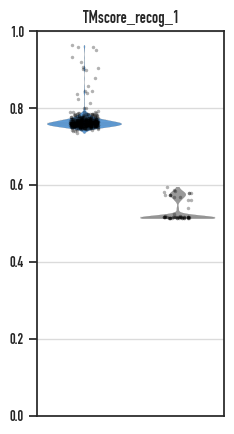

Mean scores for Fab' driven recognition (No):
TMscore_recog_1    0.532087
dtype: float64
Max scores for Fab' driven recognition (No):
TMscore_recog_1    0.59581
dtype: float64
Min scores for Fab' driven recognition (No):
TMscore_recog_1    0.51355
dtype: float64
Mean scores for Protease driven recognition (Yes):
TMscore_recog_1    0.767935
dtype: float64
Max scores for Protease driven recognition (Yes):
TMscore_recog_1    0.96468
dtype: float64
Min scores for Protease driven recognition (Yes):
TMscore_recog_1    0.73499
dtype: float64


In [ ]:
metrics_plot = [
    "TMscore_recog_1",
    ]

plot_clusters_scores(
    model_info_with_clusters, metrics_plot,
    pair="A-B", clusters=[14, 15],
    file_title="plots/AF3S_cluster_score_distributions_tm_2",
    fig_w=2.5, fig_h=4.5,
    )

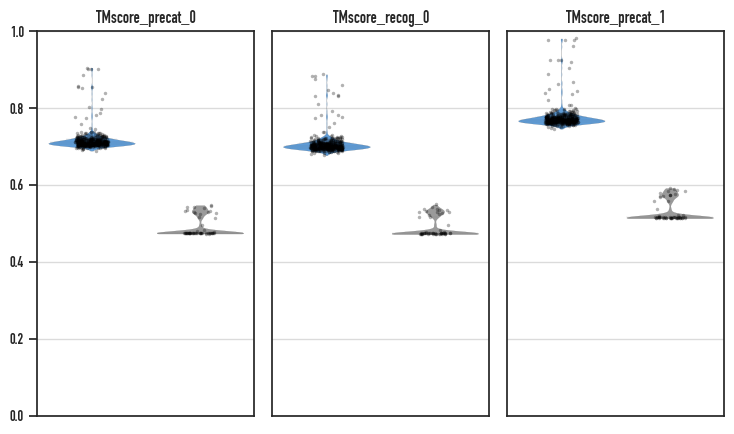

Mean scores for Fab' driven recognition (No):
TMscore_precat_0    0.490824
TMscore_recog_0     0.489531
TMscore_precat_1    0.531861
dtype: float64
Max scores for Fab' driven recognition (No):
TMscore_precat_0    0.54751
TMscore_recog_0     0.54925
TMscore_precat_1    0.59206
dtype: float64
Min scores for Fab' driven recognition (No):
TMscore_precat_0    0.47368
TMscore_recog_0     0.47223
TMscore_precat_1    0.51357
dtype: float64
Mean scores for Protease driven recognition (Yes):
TMscore_precat_0    0.717205
TMscore_recog_0     0.707586
TMscore_precat_1    0.776341
dtype: float64
Max scores for Protease driven recognition (Yes):
TMscore_precat_0    0.90544
TMscore_recog_0     0.88812
TMscore_precat_1    0.98139
dtype: float64
Min scores for Protease driven recognition (Yes):
TMscore_precat_0    0.68924
TMscore_recog_0     0.67753
TMscore_precat_1    0.74643
dtype: float64


In [ ]:
metrics_plot = [
    "TMscore_precat_0", "TMscore_recog_0",
    "TMscore_precat_1", 
    ]

plot_clusters_scores(
    model_info_with_clusters, metrics_plot,
    pair="A-B", clusters=[14, 15],
    file_title="plots/AF3S_cluster_score_distributions_tm_2",
    fig_w=2.5, fig_h=4.5,
    )

In [17]:
model_info_with_clusters = pd.read_csv(
    "AF3S_with_energies.csv"
    )

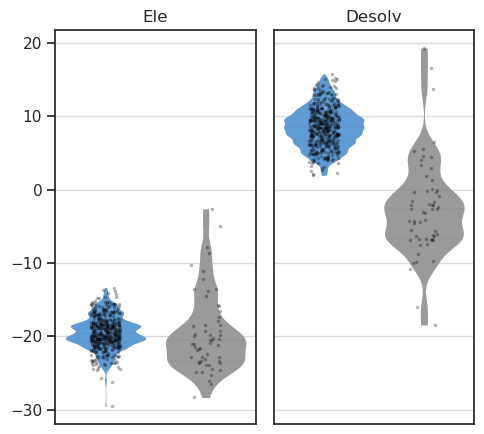

Mean scores for Fab' driven recognition (No):
Ele      -19.427158
Desolv    -2.409088
dtype: float64
Max scores for Fab' driven recognition (No):
Ele       -2.629
Desolv    19.302
dtype: float64
Min scores for Fab' driven recognition (No):
Ele      -28.356
Desolv   -18.429
dtype: float64
Mean scores for Protease driven recognition (Yes):
Ele      -19.472391
Desolv     8.567946
dtype: float64
Max scores for Protease driven recognition (Yes):
Ele      -13.354
Desolv    15.758
dtype: float64
Min scores for Protease driven recognition (Yes):
Ele      -29.535
Desolv     1.967
dtype: float64


In [ ]:
metrics_plot = [
    # "Conf",
    "Ele", "Desolv",
    # "0.1VdW-Total",
    # "1.0VdW-Total"
]
plot_clusters_energies(
    model_info_with_clusters, metrics_plot,
    clusters=[14, 15],
    file_title="plots/AF3_energies_per_cluster",
    fig_w=2.5, fig_h=4.5,
    )

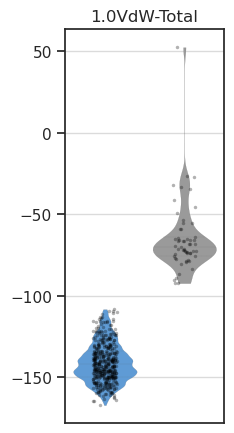

Mean scores for Fab' driven recognition (No):
1.0VdW-Total   -64.952614
dtype: float64
Max scores for Fab' driven recognition (No):
1.0VdW-Total    52.23
dtype: float64
Min scores for Fab' driven recognition (No):
1.0VdW-Total   -92.242
dtype: float64
Mean scores for Protease driven recognition (Yes):
1.0VdW-Total   -140.747582
dtype: float64
Max scores for Protease driven recognition (Yes):
1.0VdW-Total   -108.204
dtype: float64
Min scores for Protease driven recognition (Yes):
1.0VdW-Total   -166.951
dtype: float64


In [ ]:
metrics_plot = [
    # "Conf",
    # "Ele", "Desolv",
    # "0.1VdW-Total",
    "1.0VdW-Total"
]
plot_clusters_energies(
    model_info_with_clusters, metrics_plot,
    clusters=[14, 15],
    file_title="plots/AF3_energies_per_cluster_2",
    fig_w=2.5, fig_h=4.5,
    )

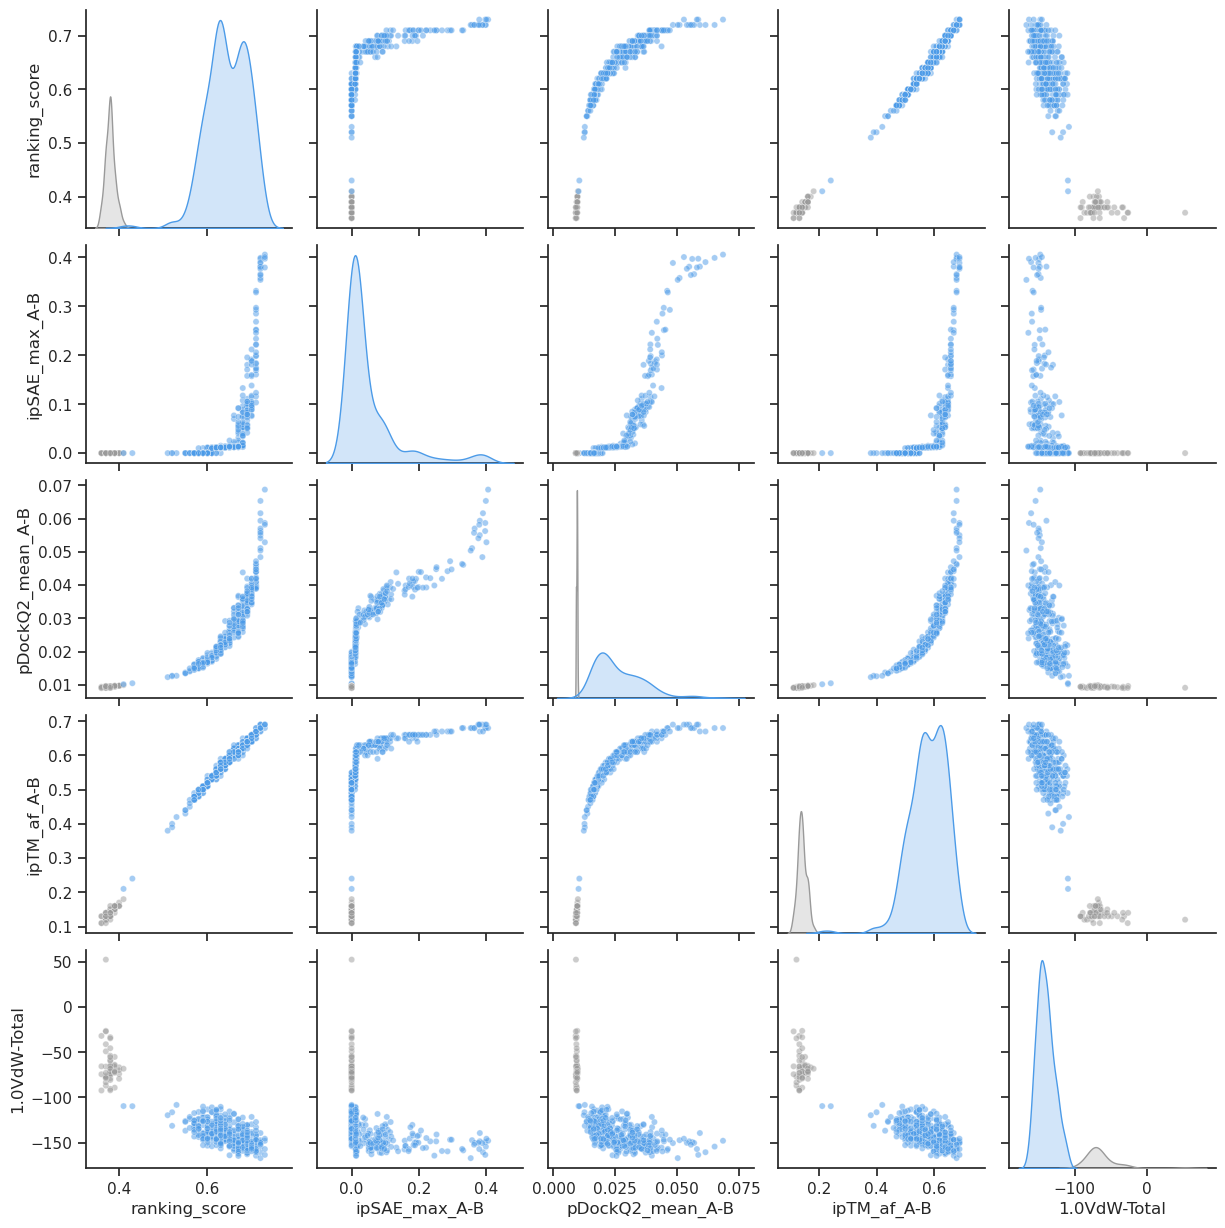

In [40]:
metrics_correl = [
    # "iptm", "ptm", 
    "ranking_score",
    "ipSAE_max_A-B", 
    # "ipSAE_max_A-C", 
    # "ipSAE_min_A-B", 
    # "ipSAE_min_A-C",
    "pDockQ2_mean_A-B", 
    # "pDockQ2_mean_A-C", 
    # "pDockQ2_mean_B-C", 
    # "LIS_mean_A-B", "LIS_mean_A-C", 
    # "LIS_mean_B-C",
    "ipTM_af_A-B",
    # "TMscore_precat_0", "TMscore_recog_0",
    "1.0VdW-Total",
    # "0.1VdW-Total",
]
plot_correlations_metrics(
    model_info_with_clusters, metrics_correl,
    clusters=[14, 15],
    fig_name="plots/correlation_metrics"
    )

In [92]:
# print the models with iptm < 0.6, 1.0VdW-Total > -125, 
# and cluster in [14, 15]

model_info_with_clusters.loc[
    (model_info_with_clusters['iptm'] < 0.5) &
    (model_info_with_clusters['1.0VdW-Total'] > -125) &
    (model_info_with_clusters['cluster'].isin([14, 15])),
    ['model_name', 'TMscore_precat_0', 'TMscore_recog_0']
]

,model_name,TMscore_precat_0,TMscore_recog_0
277,fold_igase_iga2_wt_seed_926376_model_1,0.70806,0.69837
278,fold_igase_iga2_wt_seed_926376_model_0,0.70124,0.68848
335,fold_igase_iga2_wt_seed_870265_model_1,0.71177,0.70208
338,fold_igase_iga2_wt_seed_870265_model_3,0.70803,0.69895


In [ ]:
# Calculate Z-scores for selected metrics and append to the model_info_with_clusters DataFrame
metrics_for_z_scores = [
    "iptm", "ptm", "ranking_score",
    "pDockQ2_mean_A-B", "pDockQ2_mean_A-C", 
    "LIS_mean_A-B", "LIS_mean_A-C", 
    "ipSAE_max_A-B", "ipSAE_min_A-B",
    "ipSAE_max_A-C", "ipSAE_min_A-C",
    "1.0VdW-Total",
]
z_scores_df = calc_Z_scores_for_models(
    model_info_with_clusters, metrics_for_z_scores)
models_z_scores = pd.concat(
    [model_info_with_clusters, z_scores_df], axis=1)

# Add a new column to the DF that where:
# Z_AF/pyDock-1VDW = Z_ranking_score – Z_1.0VdW-Total
models_z_scores["Z_AF-pyDock_1VDW"] = models_z_scores['Z_ranking_score'] - models_z_scores['Z_1.0VdW-Total']
models_z_scores.to_csv(
    "AF3S_with_energies_z_scores.csv",
    index=False
)
models_z_scores.head()

In [4]:
models_z_scores = pd.read_csv(
    "AF3S_with_energies_z_scores.csv"
    )

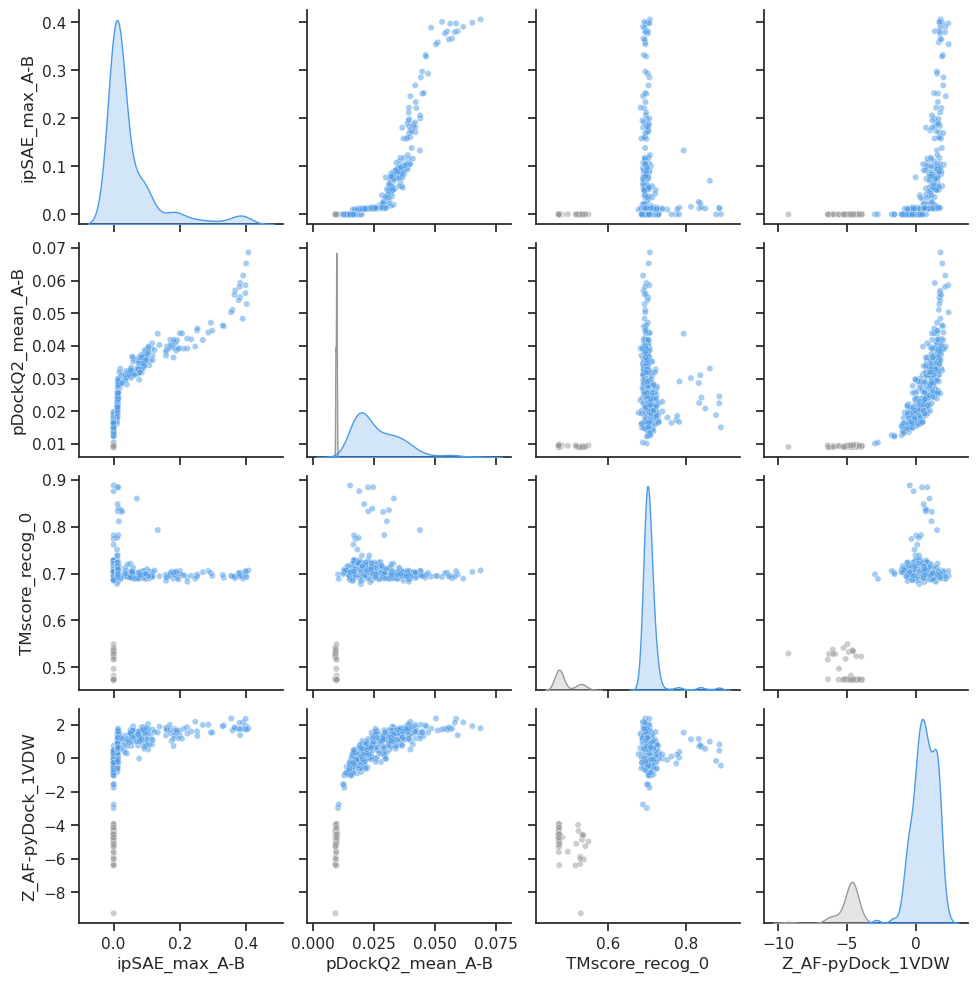

In [44]:
metrics_correl = [
    # "ranking_score",
    "ipSAE_max_A-B", 
    # "ipSAE_max_A-C", 
    # "ipSAE_min_A-B", "ipSAE_min_A-C",
    # "ipTM_af_A-B", 
    "pDockQ2_mean_A-B", 
    # "pDockQ2_mean_A-C", 
    # "LIS_mean_A-B", "LIS_mean_A-C", 
    # "TMscore_precat_0",
    "TMscore_recog_0",
    "Z_AF-pyDock_1VDW",
    # "Z_1.0VdW-Total"
]
plot_correlations_metrics(
    models_z_scores, metrics_correl,
    clusters=[14, 15],
    fig_name="plots/correlation_metrics_z_scores"
    )

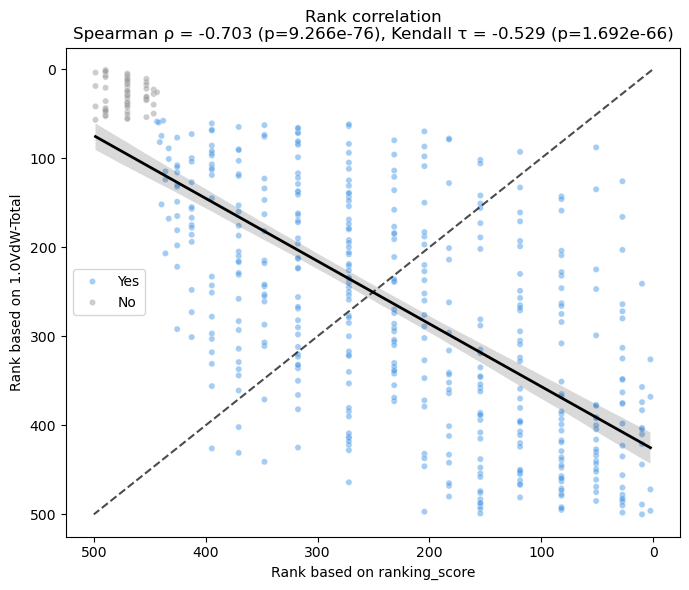

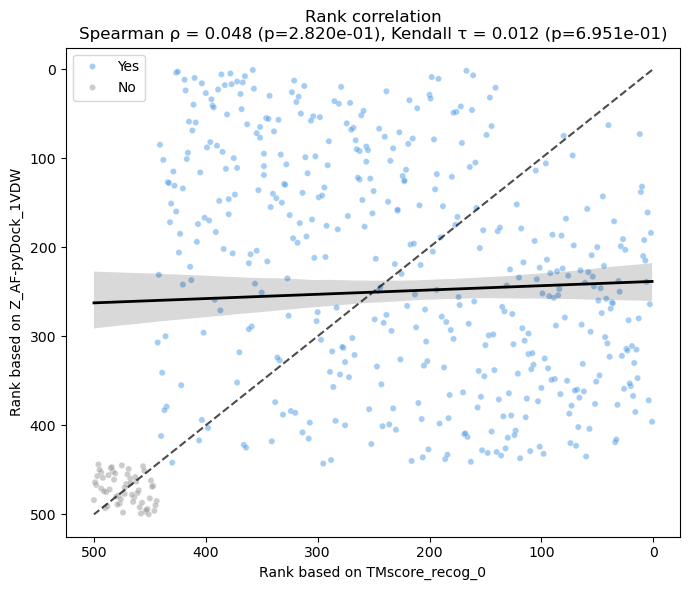

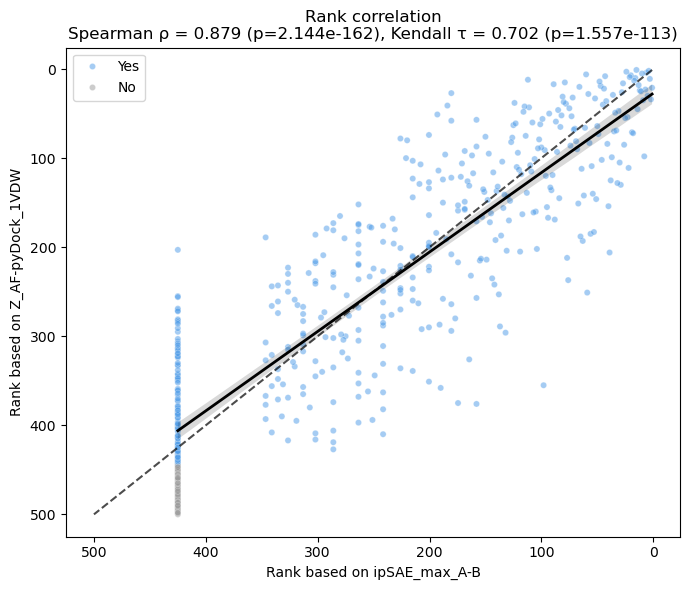

In [5]:
# Examples of rank vs rank plots for selected metrics
plot_rank_vs_rank(
    models_z_scores, 
    metric_x="ranking_score", 
    metric_y="1.0VdW-Total",
    clusters=[14, 15],
    file_path="plots/"
)
plot_rank_vs_rank(
    models_z_scores, 
    metric_x="TMscore_recog_0", 
    metric_y="Z_AF-pyDock_1VDW",
    clusters=[14, 15],
    file_path="plots/"
)
plot_rank_vs_rank(
    models_z_scores, 
    metric_x="ipSAE_max_A-B", 
    metric_y="Z_AF-pyDock_1VDW",
    clusters=[14, 15],
    file_path="plots/"
)

In [6]:
models_with_dockq = pd.read_csv(
    "AF3S_with_DockQ.csv"
    )

In [ ]:
metrics_for_z_scores = [
    "precat_TotalDockQ", 
    "precat_DockQ_AB", "precat_iRMSD_AB",
    "precat_DockQ_AC", "precat_iRMSD_AC",
    "precat_DockQ_BC", "precat_iRMSD_BC",
    "recogn_TotalDockQ",
    "recogn_DockQ_AB", "recogn_iRMSD_AB",
    "recogn_DockQ_AC", "recogn_iRMSD_AC",
    "recogn_DockQ_BC", "recogn_iRMSD_BC",
]

z_scores_dockq_df = calc_Z_scores_for_models(
    models_with_dockq, metrics_for_z_scores)
models_with_dockq_z_scores = pd.concat(
    [models_with_dockq, z_scores_dockq_df], axis=1)

models_with_dockq_z_scores.to_csv(
    "AF3S_with_DockQ_z_scores.csv",
    index=False
)
models_with_dockq_z_scores.head()

In [7]:
models_with_dockq_z_scores = pd.read_csv(
    "AF3S_with_DockQ_z_scores.csv"
    )

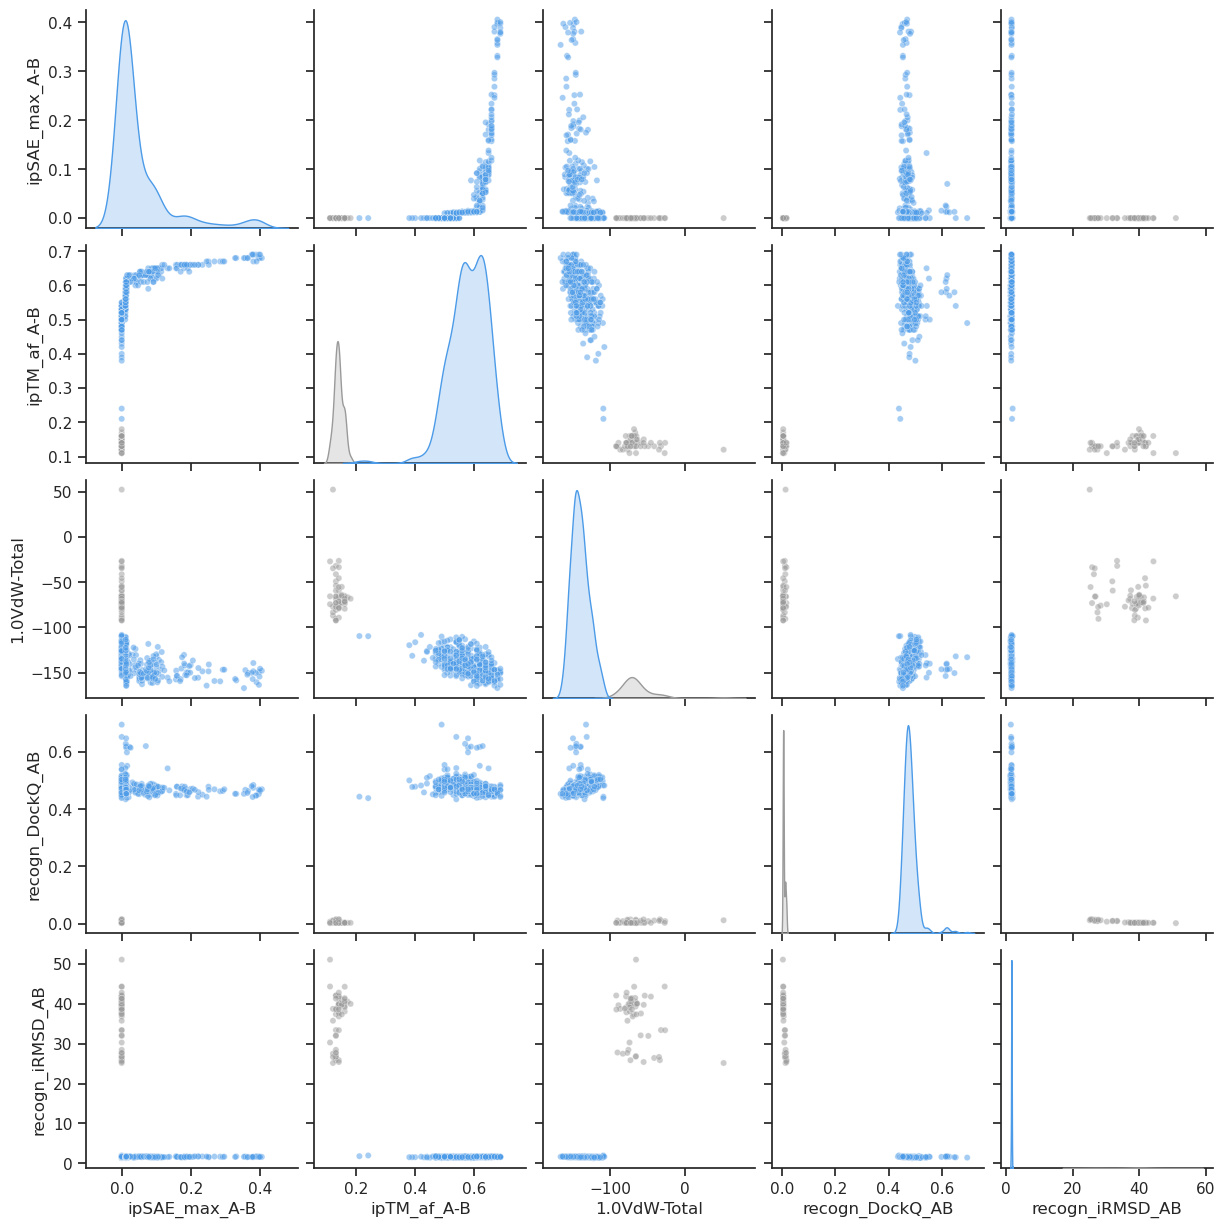

In [20]:
metrics_correl = [
    # "ranking_score",
    "ipSAE_max_A-B", 
    # "ipSAE_max_A-C", 
    # "ipSAE_min_A-B", "ipSAE_min_A-C",
    "ipTM_af_A-B",
    # "pDockQ2_mean_A-B", "pDockQ2_mean_A-C", 
    # "LIS_mean_A-B", "LIS_mean_A-C", 
    "1.0VdW-Total",
    # "TMscore_precat_0", "TMscore_recog_0",
    # "precat_TotalDockQ",
    # "precat_DockQ_AB", "precat_iRMSD_AB",
    # "precat_DockQ_AC", "precat_iRMSD_AC",
    # "precat_DockQ_BC", "precat_iRMSD_BC",
    # "recogn_TotalDockQ",
    "recogn_DockQ_AB", "recogn_iRMSD_AB",
    # "recogn_DockQ_AC", "recogn_iRMSD_AC",
    # "recogn_DockQ_BC", "recogn_iRMSD_BC",
]

plot_correlations_metrics(
    models_with_dockq_z_scores, metrics_correl,
    clusters=[14, 15],
    fig_name="plots/correlation_metrics_z_scores_dockq"
    )

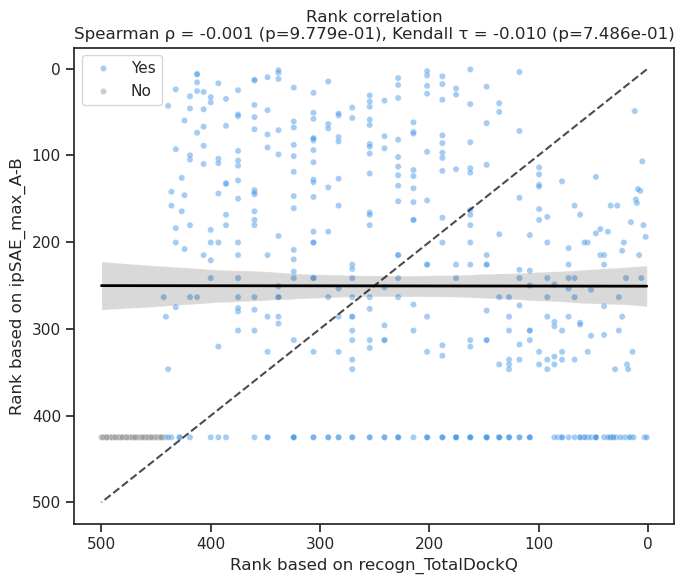

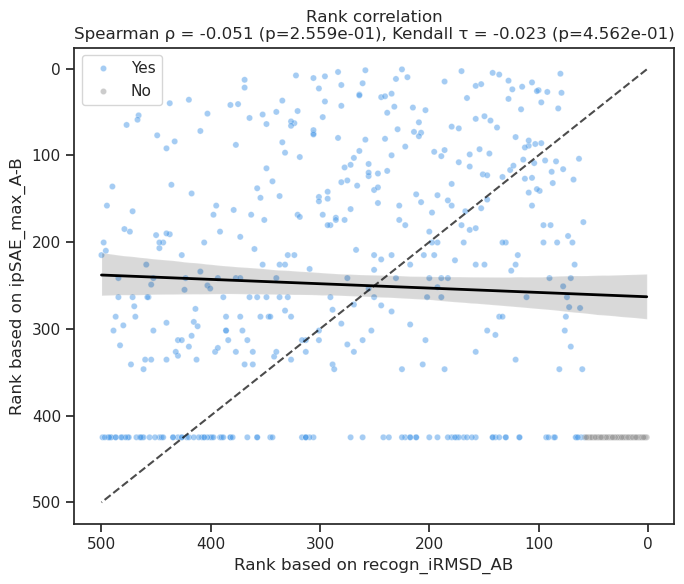

In [12]:
plot_rank_vs_rank(
    models_with_dockq_z_scores, 
    metric_x="recogn_TotalDockQ",
    metric_y="ipSAE_max_A-B",
    clusters=[14, 15],
    file_path="plots/"
)
plot_rank_vs_rank(
    models_with_dockq_z_scores, 
    metric_x="recogn_iRMSD_AB",
    metric_y="ipSAE_max_A-B",
    clusters=[14, 15],
    file_path="plots/"
)

In [16]:
models_with_dockq_z_scores = pd.read_csv(
    "AF3S_with_DockQ_z_scores.csv"
    )

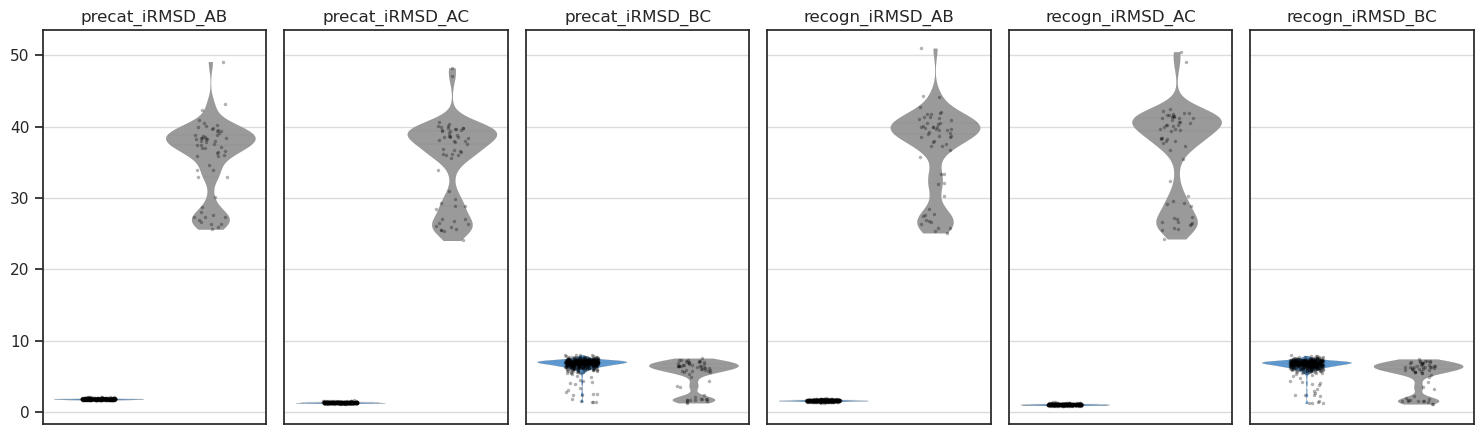

Mean scores for Fab' driven recognition (No):
precat_iRMSD_AB    35.732702
precat_iRMSD_AC    35.118333
precat_iRMSD_BC     5.255737
recogn_iRMSD_AB    36.658491
recogn_iRMSD_AC    36.426842
recogn_iRMSD_BC     5.138544
dtype: float64
Max scores for Fab' driven recognition (No):
precat_iRMSD_AB    49.134
precat_iRMSD_AC    48.252
precat_iRMSD_BC     7.552
recogn_iRMSD_AB    51.015
recogn_iRMSD_AC    50.517
recogn_iRMSD_BC     7.440
dtype: float64
Min scores for Fab' driven recognition (No):
precat_iRMSD_AB    25.651
precat_iRMSD_AC    24.069
precat_iRMSD_BC     1.309
recogn_iRMSD_AB    25.140
recogn_iRMSD_AC    24.295
recogn_iRMSD_BC     1.151
dtype: float64
Mean scores for Protease driven recognition (Yes):
precat_iRMSD_AB    1.835862
precat_iRMSD_AC    1.335747
precat_iRMSD_BC    6.710345
recogn_iRMSD_AB    1.617700
recogn_iRMSD_AC    1.056962
recogn_iRMSD_BC    6.604533
dtype: float64
Max scores for Protease driven recognition (Yes):
precat_iRMSD_AB    2.185
precat_iRMSD_AC    1.653

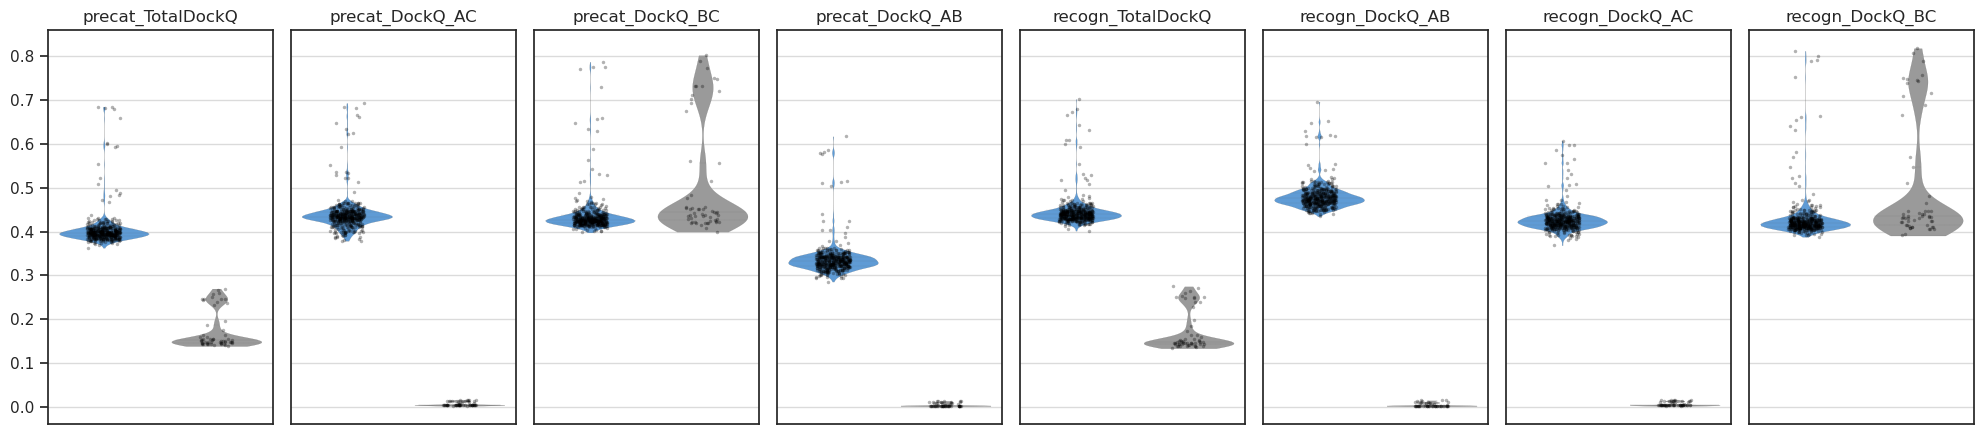

Mean scores for Fab' driven recognition (No):
precat_TotalDockQ    0.174123
precat_DockQ_AC      0.007018
precat_DockQ_BC      0.509930
precat_DockQ_AB      0.005456
recogn_TotalDockQ    0.172526
recogn_DockQ_AB      0.005544
recogn_DockQ_AC      0.006825
recogn_DockQ_BC      0.505088
dtype: float64
Max scores for Fab' driven recognition (No):
precat_TotalDockQ    0.270
precat_DockQ_AC      0.017
precat_DockQ_BC      0.802
precat_DockQ_AB      0.014
recogn_TotalDockQ    0.275
recogn_DockQ_AB      0.015
recogn_DockQ_AC      0.017
recogn_DockQ_BC      0.818
dtype: float64
Min scores for Fab' driven recognition (No):
precat_TotalDockQ    0.139
precat_DockQ_AC      0.002
precat_DockQ_BC      0.400
precat_DockQ_AB      0.002
recogn_TotalDockQ    0.134
recogn_DockQ_AB      0.002
recogn_DockQ_AC      0.002
recogn_DockQ_BC      0.391
dtype: float64
Mean scores for Protease driven recognition (Yes):
precat_TotalDockQ    0.404558
precat_DockQ_AC      0.439065
precat_DockQ_BC      0.437129
precat

In [19]:
metrics_plot = [
    "precat_iRMSD_AB", "precat_iRMSD_AC", "precat_iRMSD_BC",
    "recogn_iRMSD_AB", "recogn_iRMSD_AC", "recogn_iRMSD_BC",
]

plot_clusters_energies(
    models_with_dockq_z_scores,
    metrics_plot,
    clusters=[14, 15],
    file_title="plots/DockQ_distribution_iRMSD",
    fig_w=2.5, fig_h=4.5,
    )

metrics_plot = [
    "precat_TotalDockQ", 
    "precat_DockQ_AC", "precat_DockQ_BC",  "precat_DockQ_AB",
    "recogn_TotalDockQ",
    "recogn_DockQ_AB", "recogn_DockQ_AC", "recogn_DockQ_BC",
]

plot_clusters_energies(
    models_with_dockq_z_scores,
    metrics_plot,
    clusters=[14, 15],
    file_title="plots/DockQ_distribution",
    fig_w=2.5, fig_h=4.5,
    )